# Logistic regression

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://githubtocolab.com/EnriqueVilchezL/machine-learning/blob/main/book/03-supervised/logistic-regression/logistic-regression-notebook.ipynb)

Companion notebook for the *Logistic regression* slides. Each idea is written first by hand
with NumPy and then with the scikit-learn tool that does the same job.

**Data:** the Breast Cancer Wisconsin data (569 tumors, 30 measurements, malignant or benign).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
LEARNING_RATE = 0.1
STEPS = 500

X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)
scaler = StandardScaler().fit(X_train)
X_train, X_test = scaler.transform(X_train), scaler.transform(X_test)

## 1. The model

A linear score $z = \boldsymbol{\theta}^\top \mathbf{x} + \theta_0$ goes through the sigmoid
$\sigma(z) = \dfrac{1}{1 + e^{-z}}$, which gives the probability $P(y = 1 \mid \mathbf{x})$.

In [2]:
def sigmoid(z: np.ndarray) -> np.ndarray:
    """Squash any number into (0, 1)."""
    return 1 / (1 + np.exp(-z))


print(sigmoid(np.array([-5, 0, 2, 5])).round(3))

[0.007 0.5   0.881 0.993]


## 2. Learning the weights by hand

Gradient descent on the log-loss: $\theta_j \leftarrow \theta_j - \alpha \frac{1}{n}\sum_i (p_i - y_i)\, x_{ij}$.

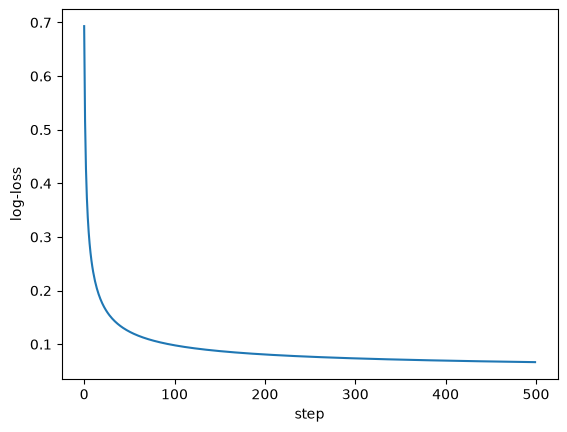

In [3]:
X_ones = np.column_stack([np.ones(len(X_train)), X_train])
theta = np.zeros(X_ones.shape[1])
losses = []
for _ in range(STEPS):
    p = sigmoid(X_ones @ theta)
    losses.append(-np.mean(y_train * np.log(p) + (1 - y_train) * np.log(1 - p)))
    theta -= LEARNING_RATE * X_ones.T @ (p - y_train) / len(y_train)

plt.plot(losses)
plt.xlabel("step")
plt.ylabel("log-loss")
plt.show()

In [4]:
p_test_by_hand = sigmoid(np.column_stack([np.ones(len(X_test)), X_test]) @ theta)
predictions_by_hand = (p_test_by_hand >= 0.5).astype(int)

model = LogisticRegression().fit(X_train, y_train)
print(f"test accuracy: by hand {np.mean(predictions_by_hand == y_test):.3f}, scikit-learn {model.score(X_test, y_test):.3f}")
print(f"same prediction on {np.mean(predictions_by_hand == model.predict(X_test)):.0%} of the test tumors")

test accuracy: by hand 0.977, scikit-learn 0.988
same prediction on 99% of the test tumors


The two weights differ a little because scikit-learn adds a small penalty on large weights
and solves the problem with a different method.

## 3. The log-loss

$J = -\frac{1}{n}\sum_i \big[y_i \log p_i + (1 - y_i)\log(1 - p_i)\big]$: confident wrong answers cost a lot.

In [5]:
p_test = model.predict_proba(X_test)[:, 1]
loss_by_hand = -np.mean(y_test * np.log(p_test) + (1 - y_test) * np.log(1 - p_test))
print(f"log-loss {loss_by_hand:.3f} | same result:", np.isclose(loss_by_hand, log_loss(y_test, p_test)))

log-loss 0.066 | same result: True


## 4. The probability comes from the weights

scikit-learn stores $\theta_0$ in `intercept_` and $\boldsymbol{\theta}$ in `coef_`; the sigmoid of the score is `predict_proba`.

In [6]:
p_from_weights = sigmoid(X_test @ model.coef_[0] + model.intercept_[0])
print("same result:", np.allclose(p_from_weights, p_test))

same result: True


## 5. Moving the threshold

Predicting class 1 when $p \ge t$: a higher threshold makes fewer but surer positive predictions.

In [7]:
for threshold in [0.3, 0.5, 0.8]:
    predicted = (p_test >= threshold).astype(int)
    print(f"t = {threshold}: precision {precision_score(y_test, predicted):.3f}, recall {recall_score(y_test, predicted):.3f}")

t = 0.3: precision 0.973, recall 1.000
t = 0.5: precision 0.991, recall 0.991
t = 0.8: precision 0.990, recall 0.944


## Exercises

1. Change `LEARNING_RATE` to 0.01 and to 2. What happens to the loss curve?
2. Compute the odds $p/(1-p)$ for three test tumors and check that their log equals the score $z$.
3. Find the feature with the largest weight in `model.coef_` and explain what $e^{\theta_j}$ means for it.